In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

Опоздаешь ли на пару? K-NN

In [ ]:
df = pd.read_csv('/content/campus-commute-late.csv')
df.head()

,trip_id,day_of_week,commute_mode,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late,is_late
0,T0001,Thu,walk,2.38,8,8,8.2,0,20.7,8,4.2,40.0,0,1
1,T0002,Tue,scooter,3.85,16,45,7.3,0,24.1,6,4.6,59.0,0,0
2,T0003,Mon,walk,1.12,9,48,7.5,0,24.0,4,4.9,36.0,0,0
3,T0004,Wed,bike,3.24,16,24,5.8,0,21.7,8,4.7,64.0,0,1
4,T0005,Fri,scooter,6.38,8,15,6.8,0,15.1,8,4.1,64.0,0,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         380 non-null    object 
 1   day_of_week     380 non-null    object 
 2   commute_mode    380 non-null    object 
 3   distance_km     380 non-null    float64
 4   leave_hour      380 non-null    int64  
 5   buffer_minutes  380 non-null    int64  
 6   sleep_hours     380 non-null    float64
 7   raining         380 non-null    int64  
 8   temperature_c   380 non-null    float64
 9   traffic_index   380 non-null    int64  
 10  backpack_kg     380 non-null    float64
 11  phone_battery   362 non-null    float64
 12  woke_late       380 non-null    int64  
 13  is_late         380 non-null    int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 41.7+ KB


Подготовка признаков

In [ ]:
df['phone_battery'] = df['phone_battery'].fillna(df['phone_battery'].median())

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         380 non-null    object 
 1   day_of_week     380 non-null    object 
 2   commute_mode    380 non-null    object 
 3   distance_km     380 non-null    float64
 4   leave_hour      380 non-null    int64  
 5   buffer_minutes  380 non-null    int64  
 6   sleep_hours     380 non-null    float64
 7   raining         380 non-null    int64  
 8   temperature_c   380 non-null    float64
 9   traffic_index   380 non-null    int64  
 10  backpack_kg     380 non-null    float64
 11  phone_battery   380 non-null    float64
 12  woke_late       380 non-null    int64  
 13  is_late         380 non-null    int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 41.7+ KB


In [ ]:
df.describe()

,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late,is_late
count,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000
mean,3.592368,10.755263,27.376316,6.832632,0.297368,16.111842,5.913158,3.678421,52.815789,0.163158,0.518421
std,1.710061,2.933853,15.125263,1.289060,0.457703,5.896597,1.879015,1.522897,22.443662,0.369997,0.500319
min,0.440000,7.000000,3.000000,3.500000,0.000000,-5.200000,1.000000,0.500000,1.000000,0.000000,0.000000
25%,2.185000,8.000000,14.000000,5.900000,0.000000,12.175000,5.000000,2.600000,37.000000,0.000000,0.000000
50%,3.695000,10.000000,28.500000,6.800000,0.000000,16.300000,6.000000,3.650000,54.000000,0.000000,1.000000
75%,4.985000,13.000000,39.000000,7.700000,1.000000,20.425000,7.000000,4.700000,67.000000,0.000000,1.000000
max,6.480000,17.000000,55.000000,10.000000,1.000000,31.400000,10.000000,7.800000,100.000000,1.000000,1.000000


In [ ]:
df.columns

Index(['trip_id', 'day_of_week', 'commute_mode', 'distance_km', 'leave_hour',
       'buffer_minutes', 'sleep_hours', 'raining', 'temperature_c',
       'traffic_index', 'backpack_kg', 'phone_battery', 'woke_late',
       'is_late'],
      dtype='object')

In [ ]:
numeric_features = ['distance_km', 'leave_hour',
       'buffer_minutes', 'sleep_hours', 'raining', 'temperature_c',
       'traffic_index', 'backpack_kg', 'phone_battery', 'woke_late']

In [ ]:
y = df['is_late']

In [ ]:
X_num = df[numeric_features]

In [ ]:
X_num.head()

,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late
0,2.38,8,8,8.2,0,20.7,8,4.2,40.0,0
1,3.85,16,45,7.3,0,24.1,6,4.6,59.0,0
2,1.12,9,48,7.5,0,24.0,4,4.9,36.0,0
3,3.24,16,24,5.8,0,21.7,8,4.7,64.0,0
4,6.38,8,15,6.8,0,15.1,8,4.1,64.0,0


In [ ]:
X_mode = pd.get_dummies(df['commute_mode'],prefix = 'mode')

In [ ]:
X_mode.head()

,mode_bike,mode_bus,mode_scooter,mode_walk
0,False,False,False,True
1,False,False,True,False
2,False,False,False,True
3,True,False,False,False
4,False,False,True,False


In [ ]:
X = pd.concat([X_num, X_mode], axis = 1)

In [ ]:
X.head()

,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late,mode_bike,mode_bus,mode_scooter,mode_walk
0,2.38,8,8,8.2,0,20.7,8,4.2,40.0,0,False,False,False,True
1,3.85,16,45,7.3,0,24.1,6,4.6,59.0,0,False,False,True,False
2,1.12,9,48,7.5,0,24.0,4,4.9,36.0,0,False,False,False,True
3,3.24,16,24,5.8,0,21.7,8,4.7,64.0,0,True,False,False,False
4,6.38,8,15,6.8,0,15.1,8,4.1,64.0,0,False,False,True,False


In [ ]:
print(X.shape)

(380, 14)


Train/Test split

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size  = 0.25, random_state=42, stratify = y
)

print("train:", X_train.shape, "test:", X_test.shape)

train: (285, 14) test: (95, 14)


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score #доля верных ответов: кол-во верн / на все ответы

In [ ]:
#KNN без Scaler

knn = KNeighborsClassifier(n_neighbors = 5)
knn.fit(X_train, y_train)

#predictions
pred = knn.predict(X_test)


print(pred)

[1 0 0 0 0 0 0 1 0 1 0 1 1 0 0 0 1 0 1 1 0 1 1 0 0 0 0 0 1 0 0 1 0 0 0 1 1
 1 0 1 1 1 1 0 1 0 0 0 1 0 1 1 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 0 1 0 0 0 0 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 1 0 0 0 0 1 0 0]


In [ ]:
accuracy = accuracy_score(y_test, pred)

print("k = 5 accuracy without scaling:", accuracy)

k = 5 accuracy without scaling: 0.5789473684210527


In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.fit_transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)

pred = knn.predict(X_test_s)

accuracy = accuracy_score(y_test, pred)

print("k = 5 accuracy with scaling:", accuracy)

k = 5 accuracy with scaling: 0.7684210526315789


In [ ]:
X_train_s[:10]

array([[-1.39720769, -0.61702628,  0.83599764, -1.76237796, -0.66286797,
        -0.58235031, -1.5941138 , -0.98547381,  0.98765302, -0.44438608,
        -0.60302269, -0.49451136, -0.5976143 ,  1.62906297],
       [-1.39720769, -1.27688553,  0.31105283, -0.4119555 ,  1.50859606,
        -0.7372532 ,  1.07523069, -0.98547381, -0.05235751, -0.44438608,
        -0.60302269, -0.49451136, -0.5976143 ,  1.62906297],
       [ 1.31851259,  0.70269222, -0.8044549 ,  2.52719927,  1.50859606,
        -0.84052179,  1.60909959, -0.04882767,  0.26416743,  2.25029549,
        -0.60302269,  2.02219824, -0.5976143 , -0.61384981],
       [ 1.52336218,  0.04283297,  0.24543472, -0.65026535,  1.50859606,
        -0.56513888,  2.14296849,  0.62020529, -0.27844676, -0.44438608,
        -0.60302269, -0.49451136, -0.5976143 ,  1.62906297],
       [ 0.63958252, -0.9469559 ,  1.16408814, -0.80913858,  1.50859606,
        -1.40849905, -0.526376  , -0.98547381, -1.04715019, -0.44438608,
        -0.60302269, -0.49

#Confusion matrix


[[37  9]
 [13 36]]


<function matplotlib.pyplot.show(close=None, block=None)>

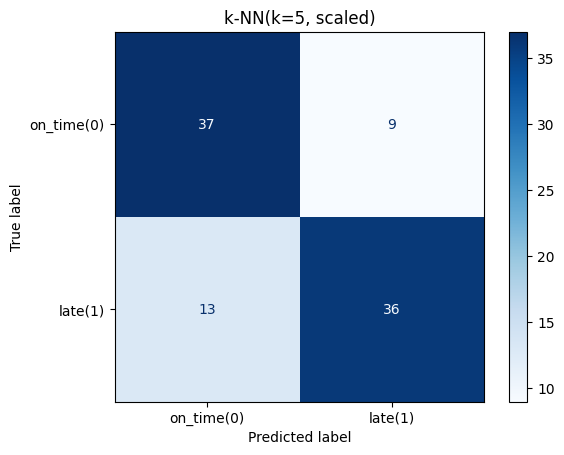

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, pred)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels=['on_time(0)', 'late(1)'])
disp.plot(cmap='Blues')
plt.title("k-NN(k=5, scaled)")
plt.show

# Задания на самостоятельную работу

1. Переберите несколько значений `k` и сравните `accuracy` на тесте. Постройте график `k` и `accuracy` которая ей соответствует

In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.fit_transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)

pred = knn.predict(X_test_s)

accuracy_5 = accuracy_score(y_test, pred)

print("k = 5 accuracy with scaling:", accuracy_5)

k = 5 accuracy with scaling: 0.7684210526315789


In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.fit_transform(X_test)

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train_s, y_train)

pred = knn.predict(X_test_s)

accuracy_10 = accuracy_score(y_test, pred)

print("k = 10 accuracy with scaling:", accuracy_10)

k = 10 accuracy with scaling: 0.8


In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.fit_transform(X_test)

knn = KNeighborsClassifier(n_neighbors=15)
knn.fit(X_train_s, y_train)

pred = knn.predict(X_test_s)

accuracy_15 = accuracy_score(y_test, pred)

print("k = 15 accuracy with scaling:", accuracy_15)

k = 15 accuracy with scaling: 0.8315789473684211


In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.fit_transform(X_test)

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X_train_s, y_train)

pred = knn.predict(X_test_s)

accuracy_20 = accuracy_score(y_test, pred)

print("k = 20 accuracy with scaling:", accuracy_20)

k = 20 accuracy with scaling: 0.8


In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.fit_transform(X_test)

knn = KNeighborsClassifier(n_neighbors=25)
knn.fit(X_train_s, y_train)

pred = knn.predict(X_test_s)

accuracy_25 = accuracy_score(y_test, pred)

print("k = 25 accuracy with scaling:", accuracy_25)

k = 25 accuracy with scaling: 0.7368421052631579


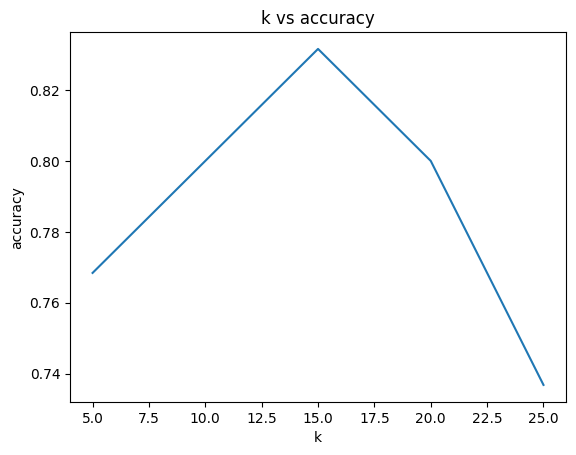

In [ ]:
accuracy_list = [accuracy_5, accuracy_10, accuracy_15, accuracy_20, accuracy_25]
k_list = [5, 10, 15, 20, 25]

plt.plot(k_list, accuracy_list)
plt.xlabel('k')
plt.ylabel('accuracy')
plt.title('k vs accuracy')
plt.show()


### Задание A

Добавьте one-hot для `day_of_week` в матрицу `X`, заново сделайте split + scaler + k-NN (`k=5`).  
Сравните accuracy с нашей моделью выше.


In [ ]:
X_mode_1 = pd.get_dummies(df['day_of_week'])
X_mode_1.head()
X = pd.concat([X_num, X_mode_1,X_mode], axis = 1)
X.head()

,distance_km,leave_hour,buffer_minutes,sleep_hours,raining,temperature_c,traffic_index,backpack_kg,phone_battery,woke_late,Fri,Mon,Thu,Tue,Wed,mode_bike,mode_bus,mode_scooter,mode_walk
0,2.38,8,8,8.2,0,20.7,8,4.2,40.0,0,False,False,True,False,False,False,False,False,True
1,3.85,16,45,7.3,0,24.1,6,4.6,59.0,0,False,False,False,True,False,False,False,True,False
2,1.12,9,48,7.5,0,24.0,4,4.9,36.0,0,False,True,False,False,False,False,False,False,True
3,3.24,16,24,5.8,0,21.7,8,4.7,64.0,0,False,False,False,False,True,True,False,False,False
4,6.38,8,15,6.8,0,15.1,8,4.1,64.0,0,True,False,False,False,False,False,False,True,False


In [ ]:
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size  = 0.25, random_state=42, stratify = y
)

print("train:", X_train.shape, "test:", X_test.shape)

train: (285, 19) test: (95, 19)


In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.fit_transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)

pred = knn.predict(X_test_s)

accuracy = accuracy_score(y_test, pred)

print("k = 5 accuracy with scaling and days:", accuracy)

k = 5 accuracy with scaling and days: 0.7263157894736842


In [ ]:
if accuracy > accuracy_5:
  print("Модель работает лучше на", accuracy-accuracy_5,"5")
else:
  print("Модель работает хуже", accuracy_5-accuracy,"%")

Модель работает хуже 0.10526315789473684 %


### Задание B

Обучите k-NN только на **двух** признаках: `distance_km` и `buffer_minutes` (со scaling).  
Какой accuracy? Почему модель слабее или неожиданно сильная?


In [ ]:
A = df[['distance_km', 'buffer_minutes']]
A.head()




,distance_km,buffer_minutes
0,2.38,8
1,3.85,45
2,1.12,48
3,3.24,24
4,6.38,15


In [ ]:
A_train,A_test,y_train,y_test = train_test_split(
    A,y,test_size  = 0.25, random_state=42, stratify = y
)

print("train:", A_train.shape, "test:", A_test.shape)

train: (285, 2) test: (95, 2)


In [ ]:
scaler = StandardScaler()
A_train_s = scaler.fit_transform(A_train)
A_test_s = scaler.fit_transform(A_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(A_train_s, y_train)

pred = knn.predict(A_test_s)

accuracy = accuracy_score(y_test, pred)

print("k = 5 accuracy with scaling distance and minutes:", accuracy)

#Модель слабее, так как меньше данных

k = 5 accuracy with scaling distance and minutes: 0.6631578947368421
